# Lab 3 · Seeing versus doing: causal inference by simulation

**Level:** Levels 2–4 · **Prerequisites:** L2-07 (read a causal graph), L2-08 (observe or intervene), L4-01 (structural causal models), L4-03 (confounders, mediators, colliders), L4-04 (back-door adjustment), L4-05 (front-door identification)

What you'll learn:

- How an intervention $do(X=x)$ differs from filtering records where $X=x$, inside a structural causal model.
- How big confounding bias is. When the confounder is measured, back-door adjustment (standardization) and inverse probability weighting remove it.
- How the front-door formula recovers an effect through a mediator, even when the confounder is hidden.
- Why conditioning on a common effect (a collider) creates a correlation that is not causal.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pozapas/quantum-causal-ai/blob/main/labs/03-causal-inference.ipynb)

In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from qcai import science as s
from qcai.viz import show

plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})

:::{note}
All data here are simulated from models we wrote down, so we know the true causal effects exactly. That is what lets us *check* each estimator. With real data the truth is unknown, and the graph is an assumption.
:::

## 1 · Predict → Run → Explain: the engine's model

`qcai.science.causal` encodes the binary structural causal model $Z\to X\to Y\leftarrow Z$:

$$Z\sim\text{Bernoulli}(0.5),\quad P(X=1\mid Z)=\begin{cases}0.8 & Z=1\\0.2 & Z=0\end{cases},\quad P(Y=1\mid X,Z)=0.1+0.2X+0.5Z .$$

**Predict.** The treatment $X$ adds 0.2 to the chance of $Y$. Will the observed difference $P(Y=1\mid X=1)-P(Y=1\mid X=0)$ also be 0.2?

In [3]:
import networkx as nx

c = s.causal()            # defaults: prevalence 0.5, low 0.2, high 0.8, base 0.1, effect 0.2, confound 0.5
print(f"P(Y=1 | X=1) = {c['treated']:.3f}    P(Y=1 | do(X=1)) = {c['do1']:.3f}")
print(f"P(Y=1 | X=0) = {c['untreated']:.3f}    P(Y=1 | do(X=0)) = {c['do0']:.3f}")
print(f"observed contrast = {c['observed']:.3f},  causal effect (ATE) = {c['ate']:.3f},  bias = {c['observed'] - c['ate']:.3f}")

P(Y=1 | X=1) = 0.700    P(Y=1 | do(X=1)) = 0.550
P(Y=1 | X=0) = 0.200    P(Y=1 | do(X=0)) = 0.350
observed contrast = 0.500,  causal effect (ATE) = 0.200,  bias = 0.300


In [4]:
assert math.isclose(c["observed"], 0.5) and math.isclose(c["ate"], 0.2)
assert math.isclose(c["do1"] - c["do0"], c["ate"])
assert math.isclose(c["observed"] - c["ate"], 0.3)

def bias_formula(prevalence, low, high, confound):
    # bias = confound x [P(Z=1 | X=1) - P(Z=1 | X=0)]
    px = prevalence * high + (1 - prevalence) * low
    return confound * (prevalence * high / px - prevalence * (1 - high) / (1 - px))

for prev, lo, hi, cf in [(0.5, 0.2, 0.8, 0.5), (0.3, 0.1, 0.6, 0.2), (0.7, 0.5, 0.5, 0.4), (0.4, 0.9, 0.3, 0.3)]:
    r = s.causal(prevalence=prev, low=lo, high=hi, confound=cf)
    assert math.isclose(r["observed"] - r["ate"], bias_formula(prev, lo, hi, cf), abs_tol=1e-12)
print("Engine and bias-formula checks passed.")

Engine and bias-formula checks passed.


**Explain.** Filtering on $X=1$ selects mostly people with $Z=1$, and $Z$ raises $Y$ by itself. So the observed contrast 0.5 mixes the treatment effect (0.2) with a confounding bias (0.3). The intervention $do(X=x)$ replaces the mechanism that assigns $X$ and leaves $Z$'s distribution unchanged. Then $P(Y=1\mid do(X=1))-P(Y=1\mid do(X=0))$ equals the effect 0.2 [@pearl].

The check cell confirms a general identity: bias $=$ (effect of $Z$ on $Y$) $\times$ (how much more common $Z$ is among the treated). When $Z$ does not influence who is treated (`low = high`), the bias is zero.

Move the slider to change how strongly $Z$ affects $Y$. The left panel compares seeing (filtering) with doing (intervening).

In [5]:
CONF = [round(0.05 * i, 2) for i in range(15)]          # 0.00 ... 0.70 keeps every probability in [0, 1]

def panel(cf):
    r = s.causal(confound=cf)
    return [r["treated"], r["untreated"], r["do1"], r["do0"]], [r["observed"], r["ate"], r["observed"] - r["ate"]]

left, right = panel(0.5)
fig = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45],
                    subplot_titles=("Seeing vs doing: P(Y = 1)", "Contrasts"))
fig.add_trace(go.Bar(x=["Y | X=1", "Y | X=0", "Y | do(X=1)", "Y | do(X=0)"], y=left,
                     marker_color=["#e67e22", "#f5cba7", "#2e86c1", "#aed6f1"],
                     hovertemplate="%{x}: %{y:.3f}<extra></extra>"), 1, 1)
fig.add_trace(go.Bar(x=["observed", "ATE", "bias"], y=right, marker_color=["#e67e22", "#2e86c1", "#c0392b"],
                     hovertemplate="%{x}: %{y:.3f}<extra></extra>"), 1, 2)
steps = []
for cf in CONF:
    l, r = panel(cf)
    steps.append(dict(method="restyle", label=f"{cf:.2f}", args=[{"y": [l, r]}, [0, 1]]))
fig.update_yaxes(range=[0, 1], row=1, col=1)
fig.update_yaxes(range=[0, 0.8], row=1, col=2)
fig.update_layout(template="plotly_white", height=430, showlegend=False,
                  sliders=[dict(active=CONF.index(0.5), steps=steps, pad=dict(t=40),
                                currentvalue=dict(prefix="confounding strength (effect of Z on Y): "))])
show(fig)

## 2 · Three graphs to keep in mind

These are the three causal graphs used in this lab. Use the buttons to switch between them. Dashed grey nodes are hidden (not measured).

In [6]:
GRAPHS = {
    "Confounder": (nx.DiGraph([("Z", "X"), ("Z", "Y"), ("X", "Y")]),
                   {"Z": (0.5, 1.0), "X": (0.0, 0.0), "Y": (1.0, 0.0)}, set()),
    "Front-door": (nx.DiGraph([("U", "X"), ("U", "Y"), ("X", "M"), ("M", "Y")]),
                   {"U": (0.5, 1.0), "X": (0.0, 0.0), "M": (0.5, 0.0), "Y": (1.0, 0.0)}, {"U"}),
    "Collider": (nx.DiGraph([("X", "C"), ("Y", "C")]),
                 {"X": (0.0, 1.0), "Y": (1.0, 1.0), "C": (0.5, 0.0)}, set()),
}
for G, _, _ in GRAPHS.values():
    assert nx.is_directed_acyclic_graph(G)

def arrows(G, pos):
    out = []
    for a, b in G.edges:
        (x0, y0), (x1, y1) = pos[a], pos[b]
        L = math.hypot(x1 - x0, y1 - y0)
        k = 0.11 / L                                    # stop the arrow at the node's edge
        out.append(dict(x=x1 - k * (x1 - x0), y=y1 - k * (y1 - y0), ax=x0 + k * (x1 - x0), ay=y0 + k * (y1 - y0),
                        xref="x", yref="y", axref="x", ayref="y", showarrow=True, arrowhead=3,
                        arrowsize=1.4, arrowwidth=2, arrowcolor="#34495e", text=""))
    return out

fig = go.Figure()
names = list(GRAPHS)
for name in names:
    G, pos, hidden = GRAPHS[name]
    nodes = list(G.nodes)
    fig.add_trace(go.Scatter(
        x=[pos[n][0] for n in nodes], y=[pos[n][1] for n in nodes], mode="markers+text", text=nodes,
        textfont=dict(size=18, color="white"), visible=(name == names[0]), hoverinfo="text",
        hovertext=[f"{n} (hidden)" if n in hidden else n for n in nodes],
        marker=dict(size=46, color=["#95a5a6" if n in hidden else "#2c3e50" for n in nodes],
                    line=dict(width=3, color=["#566573" if n in hidden else "#2c3e50" for n in nodes]),
                    symbol=["circle-dot" if n in hidden else "circle" for n in nodes])))
buttons = []
for i, name in enumerate(names):
    G, pos, _ = GRAPHS[name]
    buttons.append(dict(label=name, method="update",
                        args=[{"visible": [j == i for j in range(len(names))]},
                              {"annotations": arrows(G, pos), "title.text": f"{name} graph"}]))
G0, pos0, _ = GRAPHS[names[0]]
fig.update_layout(template="plotly_white", height=380, showlegend=False, title=f"{names[0]} graph",
                  annotations=arrows(G0, pos0),
                  xaxis=dict(visible=False, range=[-0.25, 1.25]), yaxis=dict(visible=False, range=[-0.3, 1.3]),
                  margin=dict(t=110),
                  updatemenus=[dict(type="buttons", direction="right", x=0.5, xanchor="center", y=1.28, yanchor="top",
                                    buttons=buttons)])
show(fig)

In [7]:
# d-separation facts that justify each method (networkx implements the d-separation test)
def without_outgoing(G, node):
    H = G.copy()
    H.remove_edges_from(list(G.out_edges(node)))
    return H

Gc, Gf, Gk = (GRAPHS[n][0] for n in names)
backdoor_ok = nx.is_d_separator(without_outgoing(Gc, "X"), {"X"}, {"Y"}, {"Z"})     # Z blocks the back door
backdoor_empty = nx.is_d_separator(without_outgoing(Gc, "X"), {"X"}, {"Y"}, set())
fd_xm = nx.is_d_separator(without_outgoing(Gf, "X"), {"X"}, {"M"}, set())            # no back door X -> M
fd_my = nx.is_d_separator(without_outgoing(Gf, "M"), {"M"}, {"Y"}, {"X"})            # X blocks M's back door
col_marg = nx.is_d_separator(Gk, {"X"}, {"Y"}, set())
col_cond = nx.is_d_separator(Gk, {"X"}, {"Y"}, {"C"})
print(dict(backdoor_ok=backdoor_ok, backdoor_empty=backdoor_empty, fd_xm=fd_xm, fd_my=fd_my,
           collider_marginal=col_marg, collider_given_C=col_cond))
assert backdoor_ok and not backdoor_empty
assert fd_xm and fd_my
assert col_marg and not col_cond

{'backdoor_ok': True, 'backdoor_empty': False, 'fd_xm': True, 'fd_my': True, 'collider_marginal': True, 'collider_given_C': False}


A publication-style version of the same three graphs:

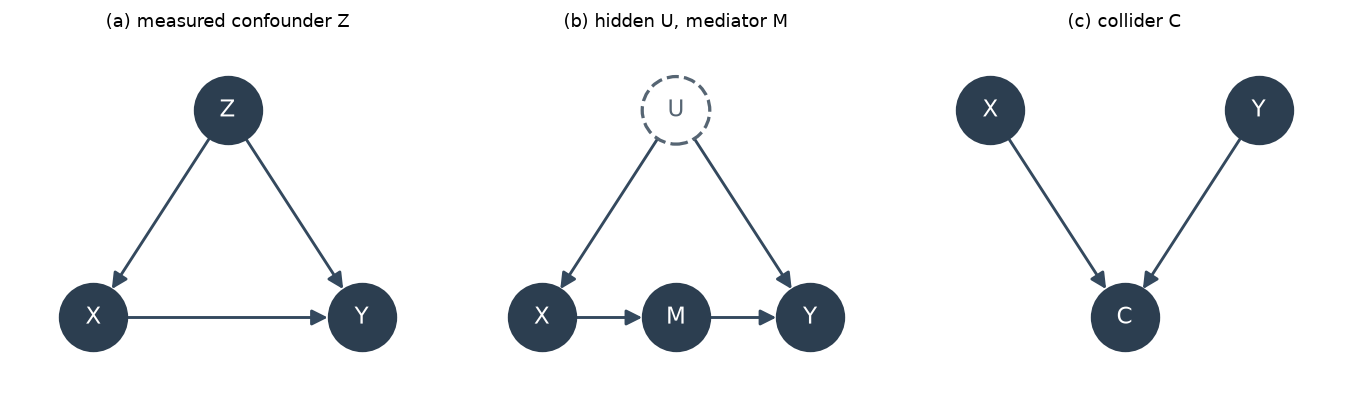

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2))
for ax, name in zip(axes, names):
    G, pos, hidden = GRAPHS[name]
    nx.draw_networkx_edges(G, pos, ax=ax, arrowstyle="-|>", arrowsize=18, width=1.6, node_size=1400,
                           edge_color="#34495e")
    vis = [n for n in G.nodes if n not in hidden]
    nx.draw_networkx_nodes(G, pos, nodelist=vis, ax=ax, node_size=1400, node_color="#2c3e50")
    if hidden:
        nx.draw_networkx_nodes(G, pos, nodelist=list(hidden), ax=ax, node_size=1400, node_color="white",
                               edgecolors="#566573", linewidths=1.8)
    nx.draw_networkx_labels(G, pos, labels={n: n for n in vis}, ax=ax, font_color="white", font_size=13)
    nx.draw_networkx_labels(G, pos, labels={n: n for n in hidden}, ax=ax, font_color="#566573", font_size=13)
    for n in hidden:
        ax.collections[-1].set_linestyle("--")
    ax.set_title({"Confounder": "(a) measured confounder Z", "Front-door": "(b) hidden U, mediator M",
                  "Collider": "(c) collider C"}[name], fontsize=10)
    ax.set_xlim(-0.3, 1.3); ax.set_ylim(-0.35, 1.35); ax.axis("off")
fig.tight_layout()
plt.show()

## 3 · Predict → Run → Explain: back-door adjustment on 20,000 records

We now draw 20,000 records from the engine's model and forget that we know the truth.

**Predict.** Which of these will land near the true effect 0.2: the naive difference, the stratified (standardized) estimate, or the inverse-probability-weighted (IPW) estimate?

In [9]:
n = 20_000
g = np.random.default_rng(20251)
PREV, LOW, HIGH, BASE, EFFECT, CONFOUND = 0.5, 0.2, 0.8, 0.1, 0.2, 0.5
Z = (g.random(n) < PREV).astype(int)
X = (g.random(n) < np.where(Z == 1, HIGH, LOW)).astype(int)
uY = g.random(n)
Y = (uY < BASE + EFFECT * X + CONFOUND * Z).astype(int)

def naive(X, Y):
    return Y[X == 1].mean() - Y[X == 0].mean()

def standardize(Z, X, Y):
    # back-door formula: sum_z [E(Y | X=1, z) - E(Y | X=0, z)] P(z)
    return sum((Y[(X == 1) & (Z == z)].mean() - Y[(X == 0) & (Z == z)].mean()) * np.mean(Z == z) for z in (0, 1))

def ipw(Z, X, Y):
    e = np.where(Z == 1, X[Z == 1].mean(), X[Z == 0].mean())       # estimated propensity P(X=1 | Z)
    return np.mean(Y * X / e) - np.mean(Y * (1 - X) / (1 - e))

# the "do" experiment: same people, same background noise uY, X set by intervention
Y_do1 = (uY < BASE + EFFECT * 1 + CONFOUND * Z).astype(int)
Y_do0 = (uY < BASE + EFFECT * 0 + CONFOUND * Z).astype(int)

est = dict(naive=naive(X, Y), standardization=standardize(Z, X, Y), ipw=ipw(Z, X, Y),
           do_simulated=Y_do1.mean() - Y_do0.mean())
for k, v in est.items():
    print(f"{k:16s} {v:+.4f}")
print(f"truth: ATE = {c['ate']:.3f}, population observed contrast = {c['observed']:.3f}")

naive            +0.4978
standardization  +0.1857
ipw              +0.1857
do_simulated     +0.2011
truth: ATE = 0.200, population observed contrast = 0.500


In [10]:
TOL = 0.03                        # checked below to be at least 3 bootstrap standard errors
assert abs(est["standardization"] - c["ate"]) < TOL
assert abs(est["ipw"] - c["ate"]) < TOL
assert abs(est["do_simulated"] - c["ate"]) < TOL
assert abs(est["naive"] - c["observed"]) < TOL and est["naive"] - c["ate"] > 0.2
assert math.isclose(est["ipw"], est["standardization"], abs_tol=1e-10)   # identical with a saturated propensity model
print("Back-door checks passed.")

Back-door checks passed.


**Explain.** The naive difference reproduces the biased population contrast.

Standardization compares treated and untreated *within* each level of $Z$. It then averages with the population weights $P(z)$. This is the back-door adjustment formula. It is valid because $Z$ blocks the only back-door path $X\leftarrow Z\to Y$ [@pearl].

IPW reweights each record by $1/P(X=x\mid Z)$. This builds a pseudo-population in which $Z$ no longer predicts $X$ [@hernan]. Here $Z$ is binary and the propensities are estimated separately in each stratum. In that case the two estimators give the same number, as the check cell confirms. Both need positivity: every stratum of $Z$ must contain treated and untreated records.

## 4 · Front-door: a hidden confounder and a mediator

Now the confounder $U$ is hidden. Treatment works only through a measured mediator $M$:

$$U\sim\text{Bern}(0.5),\quad P(X{=}1\mid U)=0.2+0.6U,\quad P(M{=}1\mid X)=0.1+0.8X,\quad P(Y{=}1\mid M,U)=0.1+0.5M+0.3U .$$

The true effect is $0.5\times0.8=0.4$. Because $U$ is unmeasured, no back-door adjustment is possible. The front-door criterion still applies, for three reasons. $M$ intercepts every directed path from $X$ to $Y$. There is no unblocked back-door path from $X$ to $M$. And $X$ blocks every back-door path from $M$ to $Y$ [@frontdoor].

**Predict.** Will "adjust for $M$" (stratify on the mediator) recover 0.4?

In [11]:
pU = {0: 0.5, 1: 0.5}
pX = lambda x, u: (0.2 + 0.6 * u) if x else 1 - (0.2 + 0.6 * u)
pM = lambda m, x: (0.1 + 0.8 * x) if m else 1 - (0.1 + 0.8 * x)
pY1 = lambda m, u: 0.1 + 0.5 * m + 0.3 * u

# exact observational distribution P(x, m, y=1) and P(x, m) by summing out the hidden U
J = {(x, m): sum(pU[u] * pX(x, u) * pM(m, x) for u in (0, 1)) for x in (0, 1) for m in (0, 1)}
JY = {(x, m): sum(pU[u] * pX(x, u) * pM(m, x) * pY1(m, u) for u in (0, 1)) for x in (0, 1) for m in (0, 1)}
Px = {x: J[(x, 0)] + J[(x, 1)] for x in (0, 1)}
Pm_x = lambda m, x: J[(x, m)] / Px[x]
Py_mx = lambda m, x: JY[(x, m)] / J[(x, m)]

def frontdoor_pop(x):
    return sum(Pm_x(m, x) * sum(Py_mx(m, xp) * Px[xp] for xp in (0, 1)) for m in (0, 1))

def do_truth(x):
    return sum(pU[u] * sum(pM(m, x) * pY1(m, u) for m in (0, 1)) for u in (0, 1))

TRUE_FD = do_truth(1) - do_truth(0)
fd_pop = frontdoor_pop(1) - frontdoor_pop(0)
naive_pop = JY[(1, 0)] / Px[1] + JY[(1, 1)] / Px[1] - JY[(0, 0)] / Px[0] - JY[(0, 1)] / Px[0]
madj_pop = sum((Py_mx(m, 1) - Py_mx(m, 0)) * (J[(0, m)] + J[(1, m)]) for m in (0, 1))
print(f"true effect {TRUE_FD:.4f} | front-door formula (population) {fd_pop:.4f} | "
      f"naive {naive_pop:.4f} | adjust-for-M {madj_pop:.4f}")

true effect 0.4000 | front-door formula (population) 0.4000 | naive 0.5800 | adjust-for-M 0.1800


In [12]:
assert math.isclose(TRUE_FD, 0.4)
assert math.isclose(fd_pop, TRUE_FD)                 # identification: exact equality in the population
assert math.isclose(naive_pop, 0.4 + 0.3 * 0.6)      # 0.58: biased by the hidden U
assert math.isclose(madj_pop, 0.3 * 0.6)             # 0.18: blocks the causal path, keeps the bias
print("Front-door identification checks passed.")

Front-door identification checks passed.


In [13]:
gf = np.random.default_rng(777)
U_ = (gf.random(n) < 0.5).astype(int)
X_ = (gf.random(n) < 0.2 + 0.6 * U_).astype(int)
M_ = (gf.random(n) < 0.1 + 0.8 * X_).astype(int)
Y_ = (gf.random(n) < 0.1 + 0.5 * M_ + 0.3 * U_).astype(int)
# U_ is now thrown away: the estimators below use only (X_, M_, Y_)

def frontdoor(X, M, Y):
    px = {x: np.mean(X == x) for x in (0, 1)}
    pm = {(m, x): np.mean(M[X == x] == m) for m in (0, 1) for x in (0, 1)}
    ey = {(m, x): Y[(M == m) & (X == x)].mean() for m in (0, 1) for x in (0, 1)}
    do = lambda x: sum(pm[(m, x)] * sum(ey[(m, xp)] * px[xp] for xp in (0, 1)) for m in (0, 1))
    return do(1) - do(0)

def adjust_for_m(X, M, Y):
    return sum((Y[(X == 1) & (M == m)].mean() - Y[(X == 0) & (M == m)].mean()) * np.mean(M == m) for m in (0, 1))

fd = dict(naive=naive(X_, Y_), adjust_for_M=adjust_for_m(X_, M_, Y_), frontdoor=frontdoor(X_, M_, Y_))
for k, v in fd.items():
    print(f"{k:14s} {v:+.4f}")

naive          +0.5894
adjust_for_M   +0.1783
frontdoor      +0.4110


In [14]:
assert abs(fd["frontdoor"] - TRUE_FD) < TOL
assert abs(fd["naive"] - naive_pop) < TOL and fd["naive"] - TRUE_FD > 0.1
assert abs(fd["adjust_for_M"] - madj_pop) < TOL and TRUE_FD - fd["adjust_for_M"] > 0.1
print("Front-door estimation checks passed.")

Front-door estimation checks passed.


**Explain.** Stratifying on $M$ blocks the very path the effect travels along. It also leaves the hidden-confounder bias in place. It lands near 0.18.

The front-door formula instead estimates two pieces it *can* identify, then chains them [@frontdoor]. The first is the effect of $X$ on $M$ (no back door). The second is the effect of $M$ on $Y$ (back door blocked by $X$). The population calculation shows that the formula equals the true effect exactly. The simulation shows that the sample estimate comes close.

The forest plot sums up every estimator in this lab with 95 % bootstrap percentile intervals (200 resamples). A 95 % interval is expected to miss the truth in about one sample in twenty. So read the printed coverage line instead of assuming every interval covers. The point is the contrast. The valid estimators sit near the truth. The biased ones miss by many times their interval width. Here standardization and IPW are the same number (one estimate, not two). Its interval just misses 0.2. This is an instance of the one-in-twenty miss, not a bias.

naive (A)              +0.498  95% CI [+0.487, +0.511]
standardization (A)    +0.186  95% CI [+0.173, +0.200]
IPW (A)                +0.186  95% CI [+0.173, +0.200]
naive (B)              +0.589  95% CI [+0.578, +0.601]
adjust for M (B)       +0.178  95% CI [+0.159, +0.200]
front-door (B)         +0.411  95% CI [+0.392, +0.427]
bootstrap standard errors: {'naive (A)': 0.0063, 'standardization (A)': 0.0075, 'IPW (A)': 0.0075, 'naive (B)': 0.0061, 'adjust for M (B)': 0.0112, 'front-door (B)': 0.009}
interval covers the true effect: {'naive (A)': False, 'standardization (A)': False, 'IPW (A)': False, 'naive (B)': False, 'adjust for M (B)': False, 'front-door (B)': True}


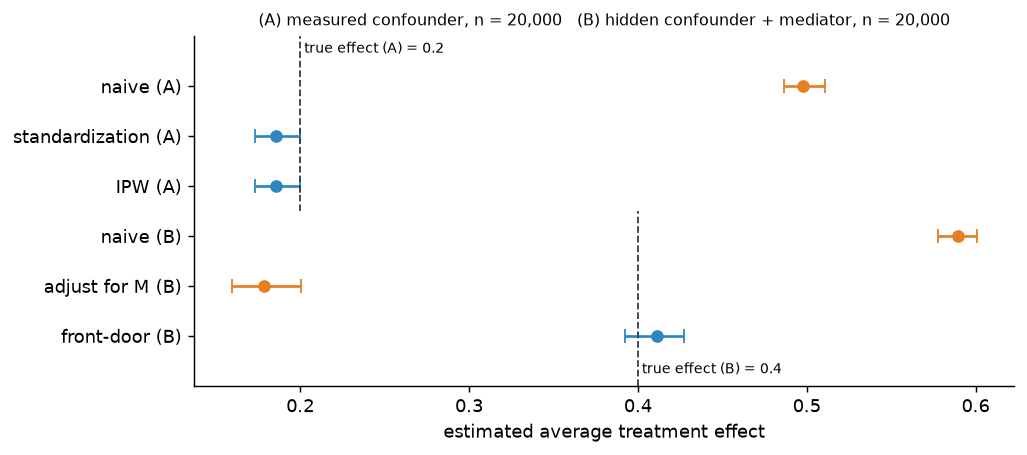

In [15]:
gb = np.random.default_rng(99)
B = 200
boots = {k: [] for k in ["naive (A)", "standardization (A)", "IPW (A)", "naive (B)", "adjust for M (B)", "front-door (B)"]}
for _ in range(B):
    i = gb.integers(0, n, n)
    boots["naive (A)"].append(naive(X[i], Y[i]))
    boots["standardization (A)"].append(standardize(Z[i], X[i], Y[i]))
    boots["IPW (A)"].append(ipw(Z[i], X[i], Y[i]))
    j = gb.integers(0, n, n)
    boots["naive (B)"].append(naive(X_[j], Y_[j]))
    boots["adjust for M (B)"].append(adjust_for_m(X_[j], M_[j], Y_[j]))
    boots["front-door (B)"].append(frontdoor(X_[j], M_[j], Y_[j]))
point = {"naive (A)": est["naive"], "standardization (A)": est["standardization"], "IPW (A)": est["ipw"],
         "naive (B)": fd["naive"], "adjust for M (B)": fd["adjust_for_M"], "front-door (B)": fd["frontdoor"]}
ci = {k: np.percentile(v, [2.5, 97.5]) for k, v in boots.items()}
for k in boots:
    print(f"{k:22s} {point[k]:+.3f}  95% CI [{ci[k][0]:+.3f}, {ci[k][1]:+.3f}]")
se = {k: float(np.std(v)) for k, v in boots.items()}
print("bootstrap standard errors:", {k: round(v, 4) for k, v in se.items()})
assert all(TOL >= 3 * se[k] for k in ("standardization (A)", "IPW (A)", "front-door (B)"))
truth = {k: (c["ate"] if k.endswith("(A)") else TRUE_FD) for k in boots}
print("interval covers the true effect:", {k: bool(ci[k][0] <= truth[k] <= ci[k][1]) for k in boots})
# The biased estimators miss by far more than their sampling uncertainty:
assert ci["naive (A)"][0] - c["ate"] > 0.2 and ci["naive (B)"][0] - TRUE_FD > 0.1
assert TRUE_FD - ci["adjust for M (B)"][1] > 0.1
# The valid estimators are within 0.02 of the truth at the edge of their interval:
for k in ("standardization (A)", "IPW (A)", "front-door (B)"):
    assert ci[k][0] - 0.02 < truth[k] < ci[k][1] + 0.02

fig, ax = plt.subplots(figsize=(8, 3.6))
labels = list(boots)
ys = np.arange(len(labels))[::-1]
good = {"standardization (A)", "IPW (A)", "front-door (B)"}
for y, k in zip(ys, labels):
    col = "#2e86c1" if k in good else "#e67e22"
    ax.errorbar(point[k], y, xerr=[[point[k] - ci[k][0]], [ci[k][1] - point[k]]], fmt="o", color=col, capsize=4)
ax.axvline(c["ate"], ymin=0.5, ymax=1, color="#2c3e50", ls="--", lw=1)
ax.axvline(TRUE_FD, ymin=0, ymax=0.5, color="#2c3e50", ls="--", lw=1)
ax.text(c["ate"], len(labels) - 0.4, " true effect (A) = 0.2", fontsize=8, va="bottom")
ax.text(TRUE_FD, -0.75, " true effect (B) = 0.4", fontsize=8)
ax.set_yticks(ys, labels)
ax.set_xlabel("estimated average treatment effect")
ax.set_title("(A) measured confounder, n = 20,000   (B) hidden confounder + mediator, n = 20,000", fontsize=9)
ax.set_ylim(-1, len(labels))
fig.tight_layout()
plt.show()

## 5 · Predict → Run → Explain: collider bias

Two traits $X$ and $Y$ are generated independently. A record is kept only if a combination of them is high, $C=\mathbb 1[X+Y+0.5\,\varepsilon>t]$. Think of admission based on two scores.

**Predict.** Among the kept records, will $X$ and $Y$ still look unrelated?

In [16]:
gc = np.random.default_rng(3)
Xc = gc.standard_normal(n)
Yc = gc.standard_normal(n)
eps = gc.standard_normal(n)
S = Xc + Yc + 0.5 * eps
THRESH = [-1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
r_all = np.corrcoef(Xc, Yc)[0, 1]
r_sel = {t: np.corrcoef(Xc[S > t], Yc[S > t])[0, 1] for t in THRESH}
kept = {t: np.mean(S > t) for t in THRESH}
print(f"correlation in all {n:,} records: {r_all:+.3f}")
for t in THRESH:
    print(f"keep if score > {t:+.1f}: kept {kept[t]:.2f} of records, correlation among kept {r_sel[t]:+.3f}")

correlation in all 20,000 records: -0.001
keep if score > -1.5: kept 0.84 of records, correlation among kept -0.195
keep if score > -1.0: kept 0.75 of records, correlation among kept -0.263
keep if score > -0.5: kept 0.63 of records, correlation among kept -0.328
keep if score > +0.0: kept 0.50 of records, correlation among kept -0.393
keep if score > +0.5: kept 0.37 of records, correlation among kept -0.449
keep if score > +1.0: kept 0.26 of records, correlation among kept -0.517
keep if score > +1.5: kept 0.16 of records, correlation among kept -0.575
keep if score > +2.0: kept 0.09 of records, correlation among kept -0.615


In [17]:
assert abs(r_all) < 0.03
assert all(r_sel[t] < -0.1 for t in THRESH)
assert r_sel[1.0] < -0.4
assert all(r_sel[a] > r_sel[b] for a, b in zip(THRESH, THRESH[1:]))   # stricter selection, stronger spurious link
print("Collider checks passed.")

Collider checks passed.


In [18]:
show_idx = np.random.default_rng(4).choice(n, 1500, replace=False)
xs, ys_, ss = Xc[show_idx], Yc[show_idx], S[show_idx]

def kept_flags(t):
    return (ss > t).astype(int).tolist()          # 1 = kept (red), 0 = dropped (grey)

def fit_line(t):
    sel = S > t
    b, a = np.polyfit(Xc[sel], Yc[sel], 1)
    return dict(type="line", x0=-3.5, x1=3.5, y0=a - 3.5 * b, y1=a + 3.5 * b, line=dict(color="#c0392b", width=3))

def title(t):
    return (f"keep if X + Y + noise > {t:+.1f}: kept {kept[t]:.0%}, correlation among kept = {r_sel[t]:+.2f} "
            f"(all records: {r_all:+.3f}); red line = fit among kept")

t0 = 1.0
fig = go.Figure(go.Scatter(x=xs.round(3).tolist(), y=ys_.round(3).tolist(), mode="markers",
                           marker=dict(size=5, color=kept_flags(t0), cmin=0, cmax=1,
                                       colorscale=[[0, "rgba(160,160,160,0.35)"], [1, "#c0392b"]]),
                           hovertemplate="X=%{x:.2f}, Y=%{y:.2f}<extra></extra>"))
steps = [dict(method="update", label=f"{t:+.1f}",
              args=[{"marker.color": [kept_flags(t)]}, {"shapes": [fit_line(t)], "title.text": title(t)}])
         for t in THRESH]
fig.update_layout(template="plotly_white", height=540, title=dict(text=title(t0), font=dict(size=12)),
                  shapes=[fit_line(t0)],
                  xaxis=dict(title="X", range=[-3.5, 3.5]), yaxis=dict(title="Y", range=[-3.5, 3.5], scaleanchor="x"),
                  sliders=[dict(active=THRESH.index(t0), steps=steps, pad=dict(t=60),
                                currentvalue=dict(prefix="selection threshold t: "))])
show(fig)

**Explain.** In the kept group, a record with a low $X$ must have had a high $Y$ to pass. So the two become negatively correlated, even though neither causes the other. Conditioning on a common effect opens the path $X\to C\leftarrow Y$. This is one form of selection bias [@hernan]. Adjusting for a variable is therefore not always safe. Adjusting for a confounder removes bias. Adjusting for a collider creates it.

## Going deeper

### Intervention in an SCM

For the engine's model, the truncated factorization gives
$P(Y=1\mid do(X=x))=\sum_z P(z)\,P(Y=1\mid x,z)=0.1+0.2x+0.5\,P(Z=1)$ [@pearl].

### Back-door adjustment

Suppose $Z$ blocks every back-door path from $X$ to $Y$ and contains no descendant of $X$. Then

$$P(y\mid do(x))=\sum_z P(y\mid x,z)\,P(z).$$

### IPW

With propensity $e(z)=P(X=1\mid Z=z)\in(0,1)$,

$$\mathbb E[Y^{1}]-\mathbb E[Y^{0}]=\mathbb E\!\left[\frac{XY}{e(Z)}\right]-\mathbb E\!\left[\frac{(1-X)Y}{1-e(Z)}\right],$$

which equals standardization when both are computed nonparametrically [@hernan].

### Front-door adjustment

Suppose $M$ satisfies the front-door criterion relative to $(X,Y)$ and $P(x,m)>0$. Then

$$P(y\mid do(x))=\sum_m P(m\mid x)\sum_{x'}P(y\mid m,x')\,P(x')$$

This is Pearl's front-door adjustment [@frontdoor].

### Confounding bias in the engine's model

$\;P(Y{=}1\mid X{=}1)-P(Y{=}1\mid X{=}0)=\text{effect}+\text{confound}\cdot\big[P(Z{=}1\mid X{=}1)-P(Z{=}1\mid X{=}0)\big]$. This is checked numerically above for several parameter sets.

## Exercises

:::{admonition} Exercise: :label: lab3-ex1
:class: tip
In `s.causal`, set `confound=0` (so $Z$ does not affect $Y$). What are the observed contrast and the bias?
:::

:::{dropdown} Solution
The observed contrast equals the effect, 0.2, and the bias is 0. Without a $Z\to Y$ arrow there is no open back-door path.
:::

:::{admonition} Exercise: :label: lab3-ex2
:class: tip
Set `low = high = 0.5`, which is what a coin-flip assignment does. What happens to the bias, even with `confound=0.5`?
:::

:::{dropdown} Solution
It is 0 again. The $Z\to X$ arrow is removed, so $Z$ is equally common among treated and untreated. This is why randomized experiments do not need back-door adjustment.
:::

:::{admonition} Exercise: :label: lab3-ex3
:class: tip
In the front-door model, add a direct arrow $X\to Y$ with strength 0.1 (so $P(Y{=}1\mid X,M,U)=0.1+0.1X+0.4M+0.3U$). Does the front-door formula still recover the true effect?
:::

:::{dropdown} Solution
No. The true effect becomes $0.1+0.4\times0.8=0.42$. The population front-door formula gives a different number (computed in the check cell). The reason is that $M$ no longer intercepts every directed path from $X$ to $Y$.
:::

## Check yourself

In [19]:
r = s.causal(confound=0)
assert math.isclose(r["observed"], 0.2) and math.isclose(r["observed"] - r["ate"], 0, abs_tol=1e-12)
r = s.causal(low=0.5, high=0.5, confound=0.5)
assert math.isclose(r["observed"] - r["ate"], 0, abs_tol=1e-12)

# Exercise 3: front-door with a direct X -> Y arrow
pY1d = lambda x, m, u: 0.1 + 0.1 * x + 0.4 * m + 0.3 * u
Jd = {(x, m): sum(pU[u] * pX(x, u) * pM(m, x) for u in (0, 1)) for x in (0, 1) for m in (0, 1)}
JYd = {(x, m): sum(pU[u] * pX(x, u) * pM(m, x) * pY1d(x, m, u) for u in (0, 1)) for x in (0, 1) for m in (0, 1)}
Pxd = {x: Jd[(x, 0)] + Jd[(x, 1)] for x in (0, 1)}
fdd = lambda x: sum(Jd[(x, m)] / Pxd[x] * sum(JYd[(xp, m)] / Jd[(xp, m)] * Pxd[xp] for xp in (0, 1)) for m in (0, 1))
truth_d = sum(pU[u] * sum(pM(m, 1) * pY1d(1, m, u) - pM(m, 0) * pY1d(0, m, u) for m in (0, 1)) for u in (0, 1))
print(f"direct-arrow model: true effect {truth_d:.4f}, front-door formula {fdd(1) - fdd(0):.4f}")
assert math.isclose(truth_d, 0.42)
assert abs((fdd(1) - fdd(0)) - truth_d) > 0.01
print("All checks passed.")

direct-arrow model: true effect 0.4200, front-door formula 0.3200
All checks passed.


:::{note} Limits of this model
- Every graph here is assumed, not learned. With real data the graph encodes untestable assumptions, and a wrong graph gives a confidently wrong answer.
- The models are binary (or Gaussian) with no measurement error, no missing data, and perfect positivity. Real estimators also need model checking, and uncertainty for model choice.
- The tolerance 0.03 in the asserts is at least three bootstrap standard errors (printed above the forest plot). A different seed gives slightly different estimates.
- The front-door formula needs *all* of its conditions. A direct $X\to Y$ path or a hidden $M$–$Y$ confounder breaks it (Exercise 3).
:::